In [38]:
from IPython.display import display
import av
import json
import io
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from PIL import Image
import plotly.express as px
from skimage.metrics import mean_squared_error as mse
from skimage.util import crop
from scipy import ndimage, datasets
from scipy.ndimage import uniform_filter, gaussian_filter
from tqdm import tqdm
import yuvio
import warnings
import sys
warnings.filterwarnings('ignore')

plt.rcParams.update({"axes.spines.top": False,
                     "axes.spines.right": False})

---

# Estimando a SSIM pra cada imagem de cada dataset

Mas antes, vou realizar alguns experimentos para verificar se estou implementando corretamente.
A dedução da estimação da SSIM pela Maria Martini é 

$$
SSIM \approx 1-\frac{MSE_l}{(2\sigma_x^2 + c_2)}
$$

onde tanto $MSE_l$ quanto $\sigma_x^2$ são locais.

No trabalho dela com o Luc, eles propõem outras 3 implementações. A primeira, é uma que não usa informações locais da imagem reconstruída, ou seja, a $MSE_l$ não está disponível, apenas a $MSE_G$. Que fica assim:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}.
$$

Vou começar implementando essa nas próximas células.

Mas, como a SSIM é aplicada por janelas, a $MSE_G$ é insuficiente para approximar a $MSE_l$. Aqui eles desenvolvem uma aproximação da $MSE_l$ a partir da $MSE_G$ com a variância local como primeira ordem de redistribuição global da distorção.

A $MSE_G$ pode ser pensada como um valor esperado da $MSE_l$. Logo, $MSE_G = \mathbb{E}[MSE_l]$.

$$MSE_l \approx MSE_G \frac{\sigma_x^2}{\mathbb{E}[\sigma_x^2]}$$

Eles fizeram uma análise empírica e encontraram que seria interessante colocar um expoente $\beta$:

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

onde $\epsilon\ =\ 1e^{-6}$ and $\beta$ ficou em 0.46 e 0.48 para cada dataset que eles usaram. Essa é outra implementação que eles fizeram. 

Como $\beta$ deu valores próximos a $0.5$, eles implementação um quarto cenário onde $\beta = 0.5$ o que resulta na variância se tornar o desvio padrão:

$$MSE_l \approx MSE_G \frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}$$

Trocando na equação inicial, fica:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}
$$

E o SSIM global é calculado pela média de todas as janelas do frame da imagem original.

$$
MSSIM(X, Y) \approx \frac{1}{M}\sum_j \left ( 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]} \right)
$$

Vou fazer os mesmos experimentos com as imagens do kodak. E depois com os LFs.

## Getting ready with kodak dataset and some fundamental functions

Primeiro vou começar definindo 2 funções importantes. Uma pra comprimir com JPEG. A outra é pra calcular a MSE de duas imagens.

In [39]:
def jpeg_compress(original, quality = 75):
    buffer = io.BytesIO()
    Image.fromarray(original, 'L').save(buffer, format = "JPEG", quality = quality)
    buffer.seek(0)
    return np.array(Image.open(buffer))

def MSE(original, pred):
    mse = np.mean(np.square(original.astype(np.float64) - pred.astype(np.float64)))
    return mse

Agora vou baixar o dataset do Kodak, direto do kaggle

In [40]:
# import kagglehub

# path_kodak_ds = kagglehub.dataset_download("sherylmehta/kodak-dataset")
try :
    open('drey.txt')
    path_kodak_ds = '/home/drey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1'
except:
    path_kodak_ds = '/home/andrey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1'
    
print("Path to dataset files:", path_kodak_ds)

Path to dataset files: /home/drey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1


\
Vou passar o nome de cada imagem do kodak pra um txt, e depois armazenar em uma lista.

In [41]:
# !ls /home/drey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1 > kodak_images.txt

A seguir temos uma lista com o nome de cada imagem do dataset do kodak

In [42]:
f = open('kodak_images.txt', 'r')
kodak_dataset = f.read().split('\n')[:-1]
kodak_dataset[:10]

['kodim01.png',
 'kodim02.png',
 'kodim03.png',
 'kodim04.png',
 'kodim05.png',
 'kodim06.png',
 'kodim07.png',
 'kodim08.png',
 'kodim09.png',
 'kodim10.png']

## Implementando a SSIM do Luc e a da Martini

Do [notebook](https://github.com/luctrudeau/approxSSIMate/blob/main/notebooks/01_ssim_psnr_foundations.ipynb) do Luc, eu tirei também a função a seguir de calculo da SSIM. Mas eu tive que dar uma alterada pois a versão dele contempla apenas o uso de um filtro uniforme. E no primeiro artigo da SSIM, eles usam um filtro gaussiano com janela 11x11 e outras características. Por isso, eu a generalizei pra incluir o uso dos dois filtros.

In [43]:
def ssim_luc(original, rec, filtro, win_size=7, data_range=255, k1=0.01, k2=0.03, mse_g = np.nan):
    '''
    Objective: Calculates the original SSIM, with the Gaussian and Uniform filters.
    To use the Gaussian, only need the radius, and sigma. To use the uniform filter, only needs the window size.
    Inputs necessary: Original and reconstructed images and the filter used.
    Returns: the mean of the SSIM for the whole image. a float value'''
    c1 = (k1 * data_range) ** 2
    c2 = (k2 * data_range) ** 2

    original = original.astype(np.float64, copy=False)
    rec = rec.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    if filtro == 'uniform':
        # Local means
        ux = uniform_filter(original, size=win_size)
        uy = uniform_filter(rec, size=win_size)
    
        # Local second moments
        uxx = uniform_filter(original * original, size=win_size)
        uyy = uniform_filter(rec * rec, size=win_size)
        uxy = uniform_filter(original * rec, size=win_size)

    elif filtro == 'gaussian':
        # Local means
        ux = gaussian_filter(original, radius=5, sigma = 1.5)
        uy = gaussian_filter(rec, radius=5, sigma = 1.5)

        # Local second moments
        uxx = gaussian_filter(original * original, radius=5, sigma = 1.5)
        uyy = gaussian_filter(rec * rec, radius=5, sigma = 1.5)
        uxy = gaussian_filter(original * rec, radius=5, sigma = 1.5)
    
    # Local variances and covariance
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)
    vy = np.maximum(cov_norm * (uyy - uy * uy), 0.0)
    vxy = cov_norm * (uxy - ux * uy)

    # SSIM formula
    A1 = 2 * ux * uy + c1
    A2 = 2 * vxy + c2   
    B1 = ux**2 + uy**2 + c1
    B2 = vx + vy + c2

    # Local SSIM
    S = (A1 * A2) / (B1 * B2)

    pad = (win_size - 1) // 2
    # Global SSIM (excluding borders)
    return crop(S, pad).mean(dtype=np.float64)

In [44]:
def ssim_martini(original, rec, filtro = '', win_size=7, data_range=255, k1=0.01, k2=0.03, mse_g = np.nan):
    '''
    Objective: Calculates the estimated SSIM, with the Martini estimation.
    Returns: the mean of the SSIM for the whole image. A float value'''
    c1 = (k1 * data_range) ** 2
    c2 = (k2 * data_range) ** 2

    original = original.astype(np.float64, copy=False)
    rec = rec.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    # Local means
    ux = uniform_filter(original, size=win_size)
    uy = uniform_filter(rec, size=win_size)

    # Local second moments
    uxx = uniform_filter(original * original, size=win_size)
    
    # Local variances and covariance
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    mse_l =  np.maximum(uniform_filter((original - rec) ** 2, size=win_size), 0.0)

    S = 1 - mse_l/ (2*vx + c2)

    pad = (win_size - 1) // 2

    return crop(S, pad).mean(dtype=np.float64)

\
Agora vou implementar uma função que deve ser usada pro cálculo de diferentes ssims, tanto a versão original, quanto as estimações.
A ideia é que retorne um data frame cujo index é cada imagem do dataset e as colunas são cada taxa de compressão. Os valores das células são as respectivas ssims calculadas.

In [45]:
def calcular_mssim_por_taxa_por_imagem(funcao_ssim, nome, rec = np.nan, filtro = 'uniforme', dataset = 'kodak'):
    '''
    Objective: calculates the SSIM following a given function to it. But for each compress tax in arange(30, 100, 5).
    Input necessary: the SSIM function, the name of the returned dataframe
    Returns: 2 dataframes, The first contains the mssim for each quality tax, of the whole dataset.
    the second contains the ssims per image and for each compress tax.'''
    qualities = np.arange(30, 99, 5)
    
    ssim_dict_por_taxa_por_imagem = {}
    
    for quality in tqdm(qualities, file = sys.stdout):
    
        ssim_lista = []

        if dataset == 'kodak':
            for image_name in kodak_dataset:
                
                path_image = path_kodak_ds + '/' + image_name
        
                img_original = Image.open(path_image).convert('L') # L de Luminancia L = R * 299/1000 + G * 587/1000 + B * 114/1000
                img_original = np.array(img_original, dtype = np.uint8)
        
                img_rec = jpeg_compress(img_original, quality = int(quality))
        
                mse_g = MSE(img_original, img_rec)
                
                mssim_de_uma_imagem = funcao_ssim(original = img_original, mse_g = mse_g, rec = img_rec, filtro = filtro)
                
                ssim_lista.append(mssim_de_uma_imagem)
    
            ssim_dict_por_taxa_por_imagem[int(quality)] = ssim_lista

            ssim_df_por_taxa_por_imagem = pd.DataFrame(ssim_dict_por_taxa_por_imagem, index = [n.replace('.png', '') for n in kodak_dataset])
            ssim_df_por_taxa_por_imagem.index = ['kodim' + str(i) for i in range(24)]

        elif dataset == 'subset':
            
            for img in subset_dataset:
                frame_.clear()

                container = av.open(path_subset + img)

                for i, frame in enumerate(container.decode(video=0)):
                    # Convert directly to a PIL.Image.Image (RGB)
                    Y = frame.to_image().convert('L')

                img_original = Y
                img_original = np.array(img_original, dtype = np.uint8)

                img_rec = jpeg_compress(img_original, quality = int(quality))
                mse_g = MSE(img_original, img_rec)

                mssim_de_uma_imagem = funcao_ssim(original = img_original, mse_g = mse_g, rec = img_rec, filtro = filtro)

                ssim_lista.append(mssim_de_uma_imagem)

            ssim_dict_por_taxa_por_imagem[int(quality)] = ssim_lista

            ssim_df_por_taxa_por_imagem = pd.DataFrame(ssim_dict_por_taxa_por_imagem, index = [n.replace('.y4m', '') for n in subset_dataset])
            ssim_df_por_taxa_por_imagem.index = ['subset' + str(i) for i in range(len(subset_dataset))]


    return ssim_df_por_taxa_por_imagem

## Implementação com $MSE_G$

A primeira implementação será com a equação usando a $MSE_G$:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}
$$

In [46]:
def mssim_global(original, mse_g, rec = 0, win_size = 7, data_range=255, k1=.01, k2=.03, filtro = 'uniform'):
    '''
    Objective: Calculate the SSIM based on the global MSE of the original and reconstructed images.
    Inputs necessary: Original image and Global MSE.
    Returns: the mean of the SSIM for the whole image.'''
    c2 = (k2*data_range)**2

    original = original.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    ux = ndimage.uniform_filter(original, size=win_size)
    uxx = ndimage.uniform_filter(original * original, size=win_size)
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    pad = (win_size - 1) // 2
    vx_c = crop(vx, pad)

    mssim = np.mean(1 - mse_g / (2*vx_c + c2))   # média de razões (a sua, sem bordas)

    return mssim

In [47]:
df_luc = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'mssim_luc', filtro = 'uniform')
df_luc.head()

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:33<00:00,  2.43s/it]


,30,35,40,45,50,55,60,65,70,75,80,85,90,95
kodim0,0.861339,0.875195,0.885985,0.895559,0.903060,0.910166,0.918015,0.926008,0.935548,0.944534,0.955443,0.967089,0.979847,0.992167
kodim1,0.852940,0.865970,0.874944,0.883361,0.890620,0.896776,0.904704,0.912622,0.920953,0.929555,0.939955,0.951281,0.965161,0.982258
kodim2,0.909747,0.918641,0.925135,0.931285,0.936460,0.940742,0.945531,0.950513,0.956141,0.961051,0.967029,0.973477,0.980475,0.988166
kodim3,0.878473,0.890035,0.898004,0.905207,0.911143,0.916675,0.922582,0.928777,0.935469,0.942117,0.950571,0.959923,0.971168,0.985036
kodim4,0.897859,0.909409,0.917820,0.925463,0.931508,0.937110,0.943143,0.949261,0.956075,0.962560,0.970087,0.977920,0.986004,0.994015


In [48]:
df_martini = calcular_mssim_por_taxa_por_imagem(ssim_martini, nome = 'mssim_martini', filtro = 'uniform')

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:23<00:00,  1.70s/it]


In [49]:
df_ssim_global = calcular_mssim_por_taxa_por_imagem(mssim_global, nome = 'mssim_global', filtro = 'uniform')

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:14<00:00,  1.00s/it]


Vou começar comparando os valores pra $SSIM(MSE_G)$ e a SSIM do luc

In [50]:
luc_medias = df_luc.mean(axis = 0)
luc_std = df_luc.std(axis = 0)

martini_medias = df_martini.mean(axis = 0)
martini_std = df_martini.std(axis = 0)

global_medias = df_ssim_global.mean(axis = 0)
global_std = df_ssim_global.std(axis = 0)

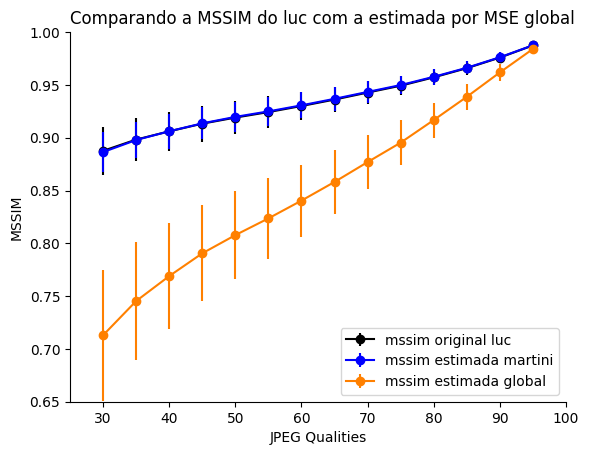

In [51]:
plt.errorbar(df_luc.columns, luc_medias, yerr = luc_std, fmt = '-o', label = 'mssim original luc', color = '#000')
plt.errorbar(df_luc.columns, martini_medias, yerr = martini_std, fmt = '-o', label = 'mssim estimada martini', color = '#0000ff')
plt.errorbar(df_luc.columns, global_medias, yerr = global_std, fmt = '-o', label = 'mssim estimada global', color = '#ff8000')
plt.legend(loc = 'lower right')

plt.title('Comparando a MSSIM do luc com a estimada por MSE global', loc = 'left')
plt.xlabel('JPEG Qualities')
plt.ylabel('MSSIM')
plt.xlim([25, 100]);
plt.ylim([0.65, 1]);

## Implementação com a $MSE_l$ estimada para $\beta \neq 0.5$ 

Lembrando que a equação a ser implementada é

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

In [52]:
def ssim_beta(original, mse_g, rec = 0, win_size=7, data_range = 255, k1=.01, k2=.03, filtro = ''):
    c2 = (k2*data_range)**2

    original = original.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    ux = ndimage.uniform_filter(original, size=win_size)
    uxx = ndimage.uniform_filter(original * original, size=win_size)
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    pad = (win_size - 1) // 2
    vx_c = crop(vx, pad)

    epsilon = 1e-6
    vx_epsilon_beta = (vx_c + epsilon)**beta
    valor_esperado = np.mean(vx_epsilon_beta)
    mse_l = (mse_g/valor_esperado)*vx_epsilon_beta
    
    mssim = np.mean(1 - mse_l / (2*vx_c + c2))   # média de razões (a sua, sem bordas)

    return mssim

In [53]:
beta = 0.46
df_ssim_beta_046 = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_046')
df_ssim_beta_046.head()

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:19<00:00,  1.38s/it]


,30,35,40,45,50,55,60,65,70,75,80,85,90,95
kodim0,0.880058,0.892995,0.902455,0.911125,0.917963,0.924525,0.931734,0.939211,0.947537,0.955783,0.965506,0.975632,0.986322,0.995604
kodim1,0.845197,0.860743,0.871091,0.880867,0.889274,0.897139,0.906087,0.915238,0.924758,0.934290,0.945679,0.958001,0.972133,0.987753
kodim2,0.890633,0.902639,0.911364,0.919582,0.926545,0.932594,0.938910,0.945532,0.952688,0.959525,0.967462,0.975767,0.984402,0.992753
kodim3,0.874986,0.888290,0.897530,0.905860,0.912630,0.918791,0.925397,0.932395,0.939871,0.947374,0.956717,0.966707,0.978053,0.990318
kodim4,0.893864,0.907140,0.916932,0.925591,0.932566,0.939027,0.945731,0.952736,0.960072,0.967129,0.975042,0.982729,0.990147,0.996566


In [54]:
beta046_medias = df_ssim_beta_046.mean(axis = 0)
beta046_std = df_ssim_beta_046.std(axis = 0)

## Implementação com a $MSE_l$ estimada para $\beta = 0.5$

In [55]:
beta = 0.5
df_ssim_beta_050 = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_050')

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:16<00:00,  1.20s/it]


In [56]:
beta050_medias = df_ssim_beta_050.mean(axis = 0)
beta050_std = df_ssim_beta_050.std(axis = 0)

## "Implementando" a função do Luc com filtro gaussiano e janela 11x11 (Zhou Wang, 2004)

In [57]:
df_ssim_gaussiano = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'ssim Bovik', filtro = 'gaussian')
gaussiano_medias = df_ssim_gaussiano.mean(axis = 0)
gaussiano_std = df_ssim_gaussiano.std(axis = 0)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:41<00:00,  2.96s/it]


## Comparando as implementações

In [58]:
# Define a função comparando_implementacoes
qualities = np.arange(30, 99, 5)

def comparando_implementacoes(medias, labels, cores, erros, titulo, xticks = [i for i in range(30, 101, 10)], yticks = [0.70, 0.80, 0.90, 1.00], loc_legend = 'best'):
    fig, ax = plt.subplots(figsize = (5, 5))

    if erros != 0:
        for media, erro, label, cor in zip (medias, erros, labels, cores):
            ax.errorbar(qualities, media, erro, fmt = '-o', label = label, color = cor, markersize = 5, ecolor=to_rgba(cor, alpha=0.4))
    else:
        for media, label, cor in zip (medias, labels, cores):
            ax.plot(qualities, media, '-o', label = label, color = cor, markersize = 4)
    
    ax.legend(loc = loc_legend)
    ax.grid()
    
    ax.set_title(titulo, loc = 'left')
    ax.set_xlabel('JPEG Quality')
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)
    ax.set_ylabel('MSSIM')
    ax.set_yticks(yticks)
    ax.set_yticklabels(yticks)
    ax.set_ylim([min(yticks), max(yticks)+.01])
    ax.set_xlim([min(xticks)-5, max(xticks)+10]);

In [59]:
d = {#'mssim original gaussiano': [gaussiano_medias, gaussiano_std, '#800080'],
     'mssim original luc': [luc_medias, luc_std, '#000'],
     'mssim estimada martini': [martini_medias, martini_std, '#0000ff'],
     'mssim estimada global': [global_medias, global_std, '#FF8C00'],
      r'mssim estimada $\beta = 0.46$': [beta046_medias, beta046_std, '#00AF00'],
      r'mssim estimada $\beta = 0.50$': [beta050_medias, beta050_std, '#FF0000']}

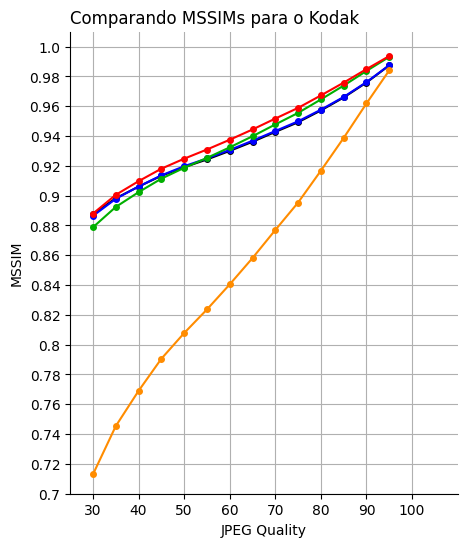

In [60]:
comparando_implementacoes(medias = [v[0] for v in d.values()], labels = d.keys(),
                          cores = [v[2] for v in d.values()], erros = 0, 
                          titulo = 'Comparando MSSIMs para o Kodak',
                         yticks = [i/100 for i in range(70, 102, 2)], loc_legend = 'lower right')
plt.gcf().set_size_inches(5, 6)
plt.gca().legend().remove()

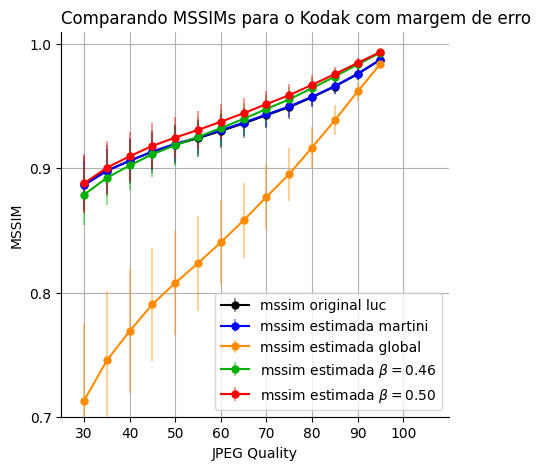

In [61]:
comparando_implementacoes(medias = [v[0] for v in d.values()], labels = d.keys(),
                          cores = [v[2] for v in d.values()], erros = [v[1] for v in d.values()], 
                          titulo = 'Comparando MSSIMs para o Kodak com margem de erro', loc_legend = 'lower right')

### Verificando o erro relativo

In [62]:
dif_media050 = ((df_luc - df_ssim_beta_050)/df_ssim_beta_050).mean()*100 # vermelho
dif_std_050 = ((df_luc - df_ssim_beta_050)/df_ssim_beta_050).std()*100

dif_media046 = ((df_luc - df_ssim_beta_046)/df_luc).mean()*100 # verde
dif_std_046 = ((df_luc - df_ssim_beta_046)/df_luc).std()*100

dif_media_martini = ((df_luc - df_martini)/df_martini).mean()*100 # azul
dif_std_martini = ((df_luc - df_martini)/df_martini).std()*100

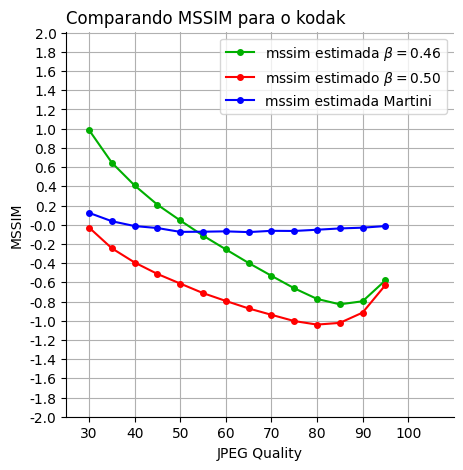

In [63]:
d = {
    r'mssim estimada $\beta = 0.46$': [dif_media046, dif_std_046, '#00AF00'],
    r'mssim estimado $\beta = 0.50$': [dif_media050, dif_std_050, '#FF0000'],
    r'mssim estimada Martini': [dif_media_martini, dif_std_martini, '#00f'],}

comparando_implementacoes(medias = [v[0] for v in d.values()], labels = d.keys(),
                          cores = [v[2] for v in d.values()], erros = 0,
                          titulo = 'Comparando MSSIM para o kodak', 
                          yticks = [round(i, 2) for i in np.arange(-2, 2.2, .2)])

---

## Testando para as imagens do Subset1

Primeiro vou obter o caminho pra elas

In [64]:
# !ls /home/drey/Downloads/subset1-y4m/ > subset1_images.txt

In [65]:
try :
    open('drey.txt')
    path_subset = '/home/drey/Downloads/subset1-y4m/'
except:
    path_subset = '/home/andrey/Downloads/subset1-y4m/'

f = open('subset1_images.txt', 'r')
subset_dataset = f.read().split('\n')
subset_dataset = [i for i in subset_dataset if '.y4m' in i]
subset_dataset[:10]

['08-2011._Panthera_tigris_tigris_-_Texas_Park_-_Lanzarote_-TP04.y4m',
 '125_-_Québec_-_Pont_de_Québec_de_nuit_-_Septembre_2009.y4m',
 '2011-03-05_03-13_Madeira_159_Funchal,_Mercado_dos_Lavradores.y4m',
 '205_-_Vallée_de_Colca_-_Panorama_-_Juin_2010_-_5_de_6.y4m',
 '89_-_Vézelay_Basilique_2.y4m',
 'Abandoned_Packard_Automobile_Factory_Detroit_200.y4m',
 'Adventure_with_the_Windmills.y4m',
 'Air_Force_Academy_Chapel,_Colorado_Springs,_CO_04090u_original.y4m',
 'Albi,_Cathédrale_Sainte_Cécile_(3).y4m',
 'Bath_from_alexandra_park.y4m']

In [66]:
frame_ = []
df_luc_s = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'mssim_luc_s', filtro = 'uniform', dataset = 'subset')

df_ssim_global_s = calcular_mssim_por_taxa_por_imagem(mssim_global, nome = 'mssim_global_s', filtro = 'uniform', dataset = 'subset')

beta = 0.46
df_ssim_beta_048_s = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_048_s', dataset = 'subset')

beta = 0.50
df_ssim_beta_050_s = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_050_s', dataset = 'subset')

# df_ssim_gaussiano_s = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'ssim Bovik_s', filtro = 'gaussian', dataset = 'subset')

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [01:22<00:00,  5.93s/it]


In [67]:
df_ssim_martini_s = calcular_mssim_por_taxa_por_imagem(ssim_martini, nome = 'ssim_martini', filtro = 'uniform', dataset = 'subset')
martini_medias_s = df_ssim_martini_s.mean(axis = 0)
martini_std_s = df_ssim_martini_s.std(axis = 0)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [01:45<00:00,  7.55s/it]


In [68]:
luc_medias_s = df_luc_s.mean(axis = 0)
luc_std_s = df_luc_s.std(axis = 0)

global_medias_s = df_ssim_global_s.mean(axis = 0)
global_std_s = df_ssim_global_s.std(axis = 0)

beta048_medias_s = df_ssim_beta_048_s.mean(axis = 0)
beta048_std_s = df_ssim_beta_048_s.std(axis = 0)

beta050_medias_s = df_ssim_beta_050_s.mean(axis = 0)
beta050_std_s = df_ssim_beta_050_s.std(axis = 0)

# gaussiano_medias_s = df_ssim_gaussiano_s.mean(axis = 0)
# gaussiano_std_s = df_ssim_gaussiano_s.std(axis = 0)

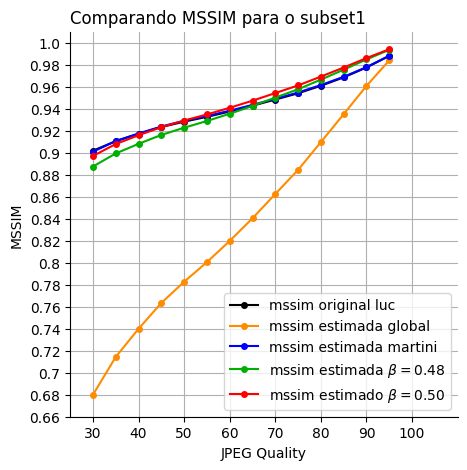

In [69]:
d_s = {
    # 'mssim original gaussiano': [gaussiano_medias_s, gaussiano_std_s, '#800080'],
    'mssim original luc': [luc_medias_s, luc_std_s, '#000'],
    'mssim estimada global': [global_medias_s, global_std_s, '#FF8C00'],
    'mssim estimada martini': [martini_medias_s, martini_std_s, '#00f'],
    r'mssim estimada $\beta = 0.48$': [beta048_medias_s, beta048_std_s, '#00AF00'],
    r'mssim estimado $\beta = 0.50$': [beta050_medias_s, beta050_std_s, '#FF0000']
}

comparando_implementacoes(medias = [v[0] for v in d_s.values()], labels = d_s.keys(),
                          cores = [v[2] for v in d_s.values()], erros = 0,
                          titulo = 'Comparando MSSIM para o subset1', 
                          yticks = [i/100 for i in range(66, 101, 2)])

## Erro relativo Subset1

In [70]:
dif_media050_s = ((df_luc_s - df_ssim_beta_050_s)/df_luc_s).mean()*100 # vermelho
dif_std_050_s = ((df_luc_s - df_ssim_beta_050_s)/df_luc_s).std()*100

dif_media048_s = ((df_luc_s - df_ssim_beta_048_s)/df_luc_s).mean()*100 # verde
dif_std_048_s = ((df_luc_s - df_ssim_beta_048_s)/df_luc_s).std()*100

dif_media_martini_s = ((df_luc_s - df_ssim_martini_s)/df_luc_s).mean()*100 # azul
dif_std_martini_s = ((df_luc_s - df_ssim_martini_s)/df_luc_s).std()*100

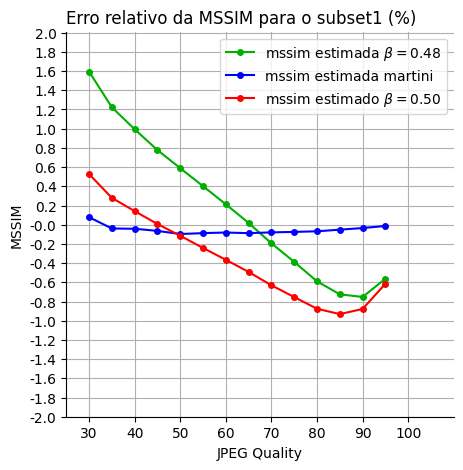

In [71]:
d_s = {
    r'mssim estimada $\beta = 0.48$': [dif_media048_s, dif_std_048_s, '#00AF00'],
    r'mssim estimada martini': [dif_media_martini_s, dif_std_martini_s, '#00f'],
    r'mssim estimado $\beta = 0.50$': [dif_media050_s, dif_std_050_s, '#FF0000']}

comparando_implementacoes(medias = [v[0] for v in d_s.values()], labels = d_s.keys(),
                          cores = [v[2] for v in d_s.values()], erros = 0,
                          titulo = 'Erro relativo da MSSIM para o subset1 (%)', 
                          yticks = [round(i, 2) for i in np.arange(-2, 2.2, .2)])

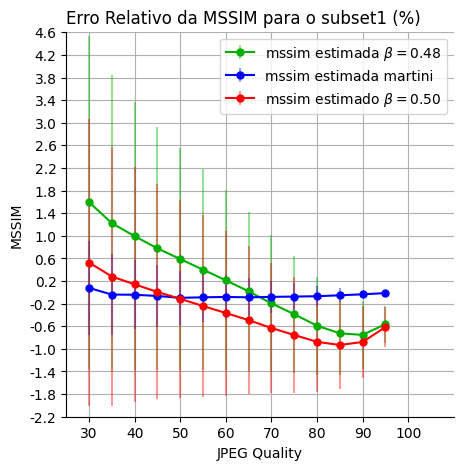

In [72]:
d_s = {
    r'mssim estimada $\beta = 0.48$': [dif_media048_s, dif_std_048_s, '#00AF00'],
    r'mssim estimada martini': [dif_media_martini_s, dif_std_martini_s, '#00f'],
    r'mssim estimado $\beta = 0.50$': [dif_media050_s, dif_std_050_s, '#FF0000']}

comparando_implementacoes(medias = [v[0] for v in d_s.values()], labels = d_s.keys(),
                          cores = [v[2] for v in d_s.values()], erros = [v[1] for v in d_s.values()],
                          titulo = 'Erro Relativo da MSSIM para o subset1 (%)', 
                          yticks = [round(i, 2) for i in np.arange(-2.2, 5, .4)])